# **Classification of Mushrooms and Beans**

Our team use the UCI Bean Dataset and the UCI Mushroom dataset in which we want to implement a random forest with these dataset. For the mushroom dataset, we want to predict whether a mushroom is labeled edible or poisonous from its characteristics. For the bean dataset, we want to predict the variety of dry bean based on its physical measurements.



 ## **Obtaining the Dataset**

In [45]:
#Allow the notebook to download and use datasets from the UCI ML repo
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo
import pandas as pd #Used to make dataframe
from sklearn.model_selection import train_test_split #train the data
from sklearn.ensemble import RandomForestClassifier #Random Forest Calculation
from sklearn.metrics import accuracy_score, classification_report #Evaluate the model
from sklearn.metrics import confusion_matrix #Compares answer with predictions
import seaborn as sns #Create charts
import matplotlib.pyplot as plt #Display the charts

In [46]:
#Fetch the dataset from the UCI
mushroom = fetch_ucirepo(id=73)
dry_bean = fetch_ucirepo(id=602)

#Turn the dataset into a dataframe
mushroom_X = mushroom.data.features.copy()
mushroom_y = mushroom.data.targets.iloc[:, 0].copy()

dry_bean_X = dry_bean.data.features.copy()
dry_bean_y = dry_bean.data.targets.iloc[:, 0].copy()

#Target is what model will be trying to predict. "x" represent the rows and "y" represent the features
print("Mushroom target:", mushroom_y.name)
print("Mushroom features:", mushroom_X.shape)

print("Dry Bean target:", dry_bean_y.name)
print("Dry Bean features:", dry_bean_X.shape)

Mushroom target: poisonous
Mushroom features: (8124, 22)
Dry Bean target: Class
Dry Bean features: (13611, 16)


In [47]:
#Show the characteristics for mushroom for the top 5 value
display(mushroom_X.head())

print("Mushroom Classes")
print(mushroom_y.value_counts())

,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,x,s,n,t,p,f,c,n,k,e,...,s,w,w,p,w,o,p,k,s,u
1,x,s,y,t,a,f,c,b,k,e,...,s,w,w,p,w,o,p,n,n,g
2,b,s,w,t,l,f,c,b,n,e,...,s,w,w,p,w,o,p,n,n,m
3,x,y,w,t,p,f,c,n,n,e,...,s,w,w,p,w,o,p,k,s,u
4,x,s,g,f,n,f,w,b,k,t,...,s,w,w,p,w,o,e,n,a,g


Mushroom Classes
poisonous
e    4208
p    3916
Name: count, dtype: int64


In [48]:
#Show the characteristics for mushroom for the top 5 value
display(dry_bean_X.head())

print("Dry Bean classes")
print(dry_bean_y.value_counts())

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166


Dry Bean classes
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


## **Dataset Information**

### Mushroom

### Target

We are targeting the `Class` variable which identifies:

- `e` = edible
- `p` = poisonous

### Attributes

| attribute | values |
|---|---|
| `cap-shape` | Bell (`b`), conical (`c`), convex (`x`), flat (`f`), knobbed (`k`), sunken (`s`) |
| `cap-surface` | Fibrous (`f`), grooves (`g`), scaly (`y`), smooth (`s`) |
| `cap-color` | Brown (`n`), buff (`b`), cinnamon (`c`), gray (`g`), green (`r`), pink (`p`), purple (`u`), red (`e`), white (`w`), yellow (`y`) |
| `bruises` | Bruises (`t`), no bruises (`f`) |
| `odor` | Almond (`a`), anise (`l`), creosote (`c`), fishy (`y`), foul (`f`), musty (`m`), none (`n`), pungent (`p`), spicy (`s`) |
| `gill-attachment` | Attached (`a`), descending (`d`), free (`f`), notched (`n`) |
| `gill-spacing` | Close (`c`), crowded (`w`), distant (`d`) |
| `gill-size` | Broad (`b`), narrow (`n`) |
| `gill-color` | Black (`k`), brown (`n`), buff (`b`), chocolate (`h`), gray (`g`), green (`r`), orange (`o`), pink (`p`), purple (`u`), red (`e`), white (`w`), yellow (`y`) |
| `stalk-shape` | Enlarging (`e`), tapering (`t`) |
| `stalk-root` | Bulbous (`b`), club (`c`), cup (`u`), equal (`e`), rhizomorphs (`z`), rooted (`r`), missing (`?`) |
| `stalk-surface-above-ring` | Fibrous (`f`), scaly (`y`), silky (`k`), smooth (`s`) |
| `stalk-surface-below-ring` | Fibrous (`f`), scaly (`y`), silky (`k`), smooth (`s`) |
| `stalk-color-above-ring` | Brown (`n`), buff (`b`), cinnamon (`c`), gray (`g`), orange (`o`), pink (`p`), red (`e`), white (`w`), yellow (`y`) |
| `stalk-color-below-ring` | Brown (`n`), buff (`b`), cinnamon (`c`), gray (`g`), orange (`o`), pink (`p`), red (`e`), white (`w`), yellow (`y`) |
| `veil-type` | Partial (`p`), universal (`u`) |
| `veil-color` | Brown (`n`), orange (`o`), white (`w`), yellow (`y`) |
| `ring-number` | None (`n`), one (`o`), two (`t`) |
| `ring-type` | Cobwebby (`c`), evanescent (`e`), flaring (`f`), large (`l`), none (`n`), pendant (`p`), sheathing (`s`), zone (`z`) |
| `spore-print-color` | Black (`k`), brown (`n`), buff (`b`), chocolate (`h`), green (`r`), orange (`o`), purple (`u`), white (`w`), yellow (`y`) |
| `population` | Abundant (`a`), clustered (`c`), numerous (`n`), scattered (`s`), several (`v`), solitary (`y`) |
| `habitat` | Grasses (`g`), leaves (`l`), meadows (`m`), paths (`p`), urban (`u`), waste (`w`), woods (`d`) |

### Dry Bean

### Target

We are targeting the `Class` variable which has a variety of beans:

- `BARBUNYA` = Barbunya bean
- `BOMBAY` = Bombay bean
- `CALI` = Cali bean
- `DERMASON` = Dermason bean
- `HOROZ` = Horoz bean
- `SEKER` = Seker bean
- `SIRA` = Sira bean

### Attributes

| Attribute | Description |
|---|---|
| `Area` | The number of pixels inside the bean |
| `Perimeter` | The length of the bean’s outer boundary |
| `MajorAxisLength` | The length of the bean’s longest axis |
| `MinorAxisLength` | The length of the bean’s shortest axis |
| `AspectRation` | The ratio between the major axis and minor axis lengths |
| `Eccentricity` | Measures how much the bean shape differs from a circle |
| `ConvexArea` | The area of the smallest convex shape surrounding the bean |
| `EquivDiameter` | The diameter of a circle with the same area as the bean |
| `Extent` | The ratio of the bean area to the area of its bounding box |
| `Solidity` | The ratio of the bean area to its convex area |
| `roundness` | Measures how closely the bean resembles a circle |
| `Compactness` | Measures how compact or tightly shaped the bean is |
| `ShapeFactor1` | A measurement describing the bean’s shape |
| `ShapeFactor2` | A measurement describing the bean’s shape |
| `ShapeFactor3` | A measurement describing the bean’s shape |
| `ShapeFactor4` | A measurement describing the bean’s shape |

Unlike the Mushroom Dataset, the Dry Bean Dataset contains numerical features. Therefore, one-hot encoding is not required. The Random Forest can use these physical measurements directly to predict the bean variety.

 ## **Prepare the Data**
 We want to train and test the data for the random forest algorithms


### Mushroom

In [49]:
mushroom_X_encoded = pd.get_dummies(mushroom_X) #Turn the text into number

mushroom_X_train, mushroom_X_test, mushroom_y_train, mushroom_y_test = train_test_split(
    mushroom_X_encoded,
    mushroom_y,
    test_size=0.2, #Train 80% and test 20%
    random_state=23, #Starting point
    stratify=mushroom_y
)

print("Training set:", mushroom_X_train.shape)
print("Testing set:", mushroom_X_test.shape)

dry_bean_X_train, dry_bean_X_test, dry_bean_y_train, dry_bean_y_test = train_test_split(
    dry_bean_X,
    dry_bean_y,
    test_size=0.2,
    random_state=23,
    stratify=dry_bean_y
)


print("Training set:", dry_bean_X_train.shape)
print("Testing set:", dry_bean_X_test.shape)

Training set: (6499, 116)
Testing set: (1625, 116)
Training set: (10888, 16)
Testing set: (2723, 16)


### Bean

In [50]:
dry_bean_X_train, dry_bean_X_test, dry_bean_y_train, dry_bean_y_test = train_test_split(
    dry_bean_X,
    dry_bean_y,
    test_size=0.2,
    random_state=23,
    stratify=dry_bean_y
)


print("Training set:", dry_bean_X_train.shape)
print("Testing set:", dry_bean_X_test.shape)

Training set: (10888, 16)
Testing set: (2723, 16)


 ## **Random Forest Calculation**
 We will be calculating using the Random Forest Algorithms

In [51]:
Forest_model = RandomForestClassifier(
    n_estimators=100, #Amount of Decisions Trees you want to build
    random_state=23 #Starting point
)

### Random Forest Mushroom

In [52]:
# Train the random forest model with encoded features
Forest_model.fit(
    mushroom_X_train,
    mushroom_y_train
)

# Make predictions for the test data
mushroom_predictions = Forest_model.predict(mushroom_X_test)

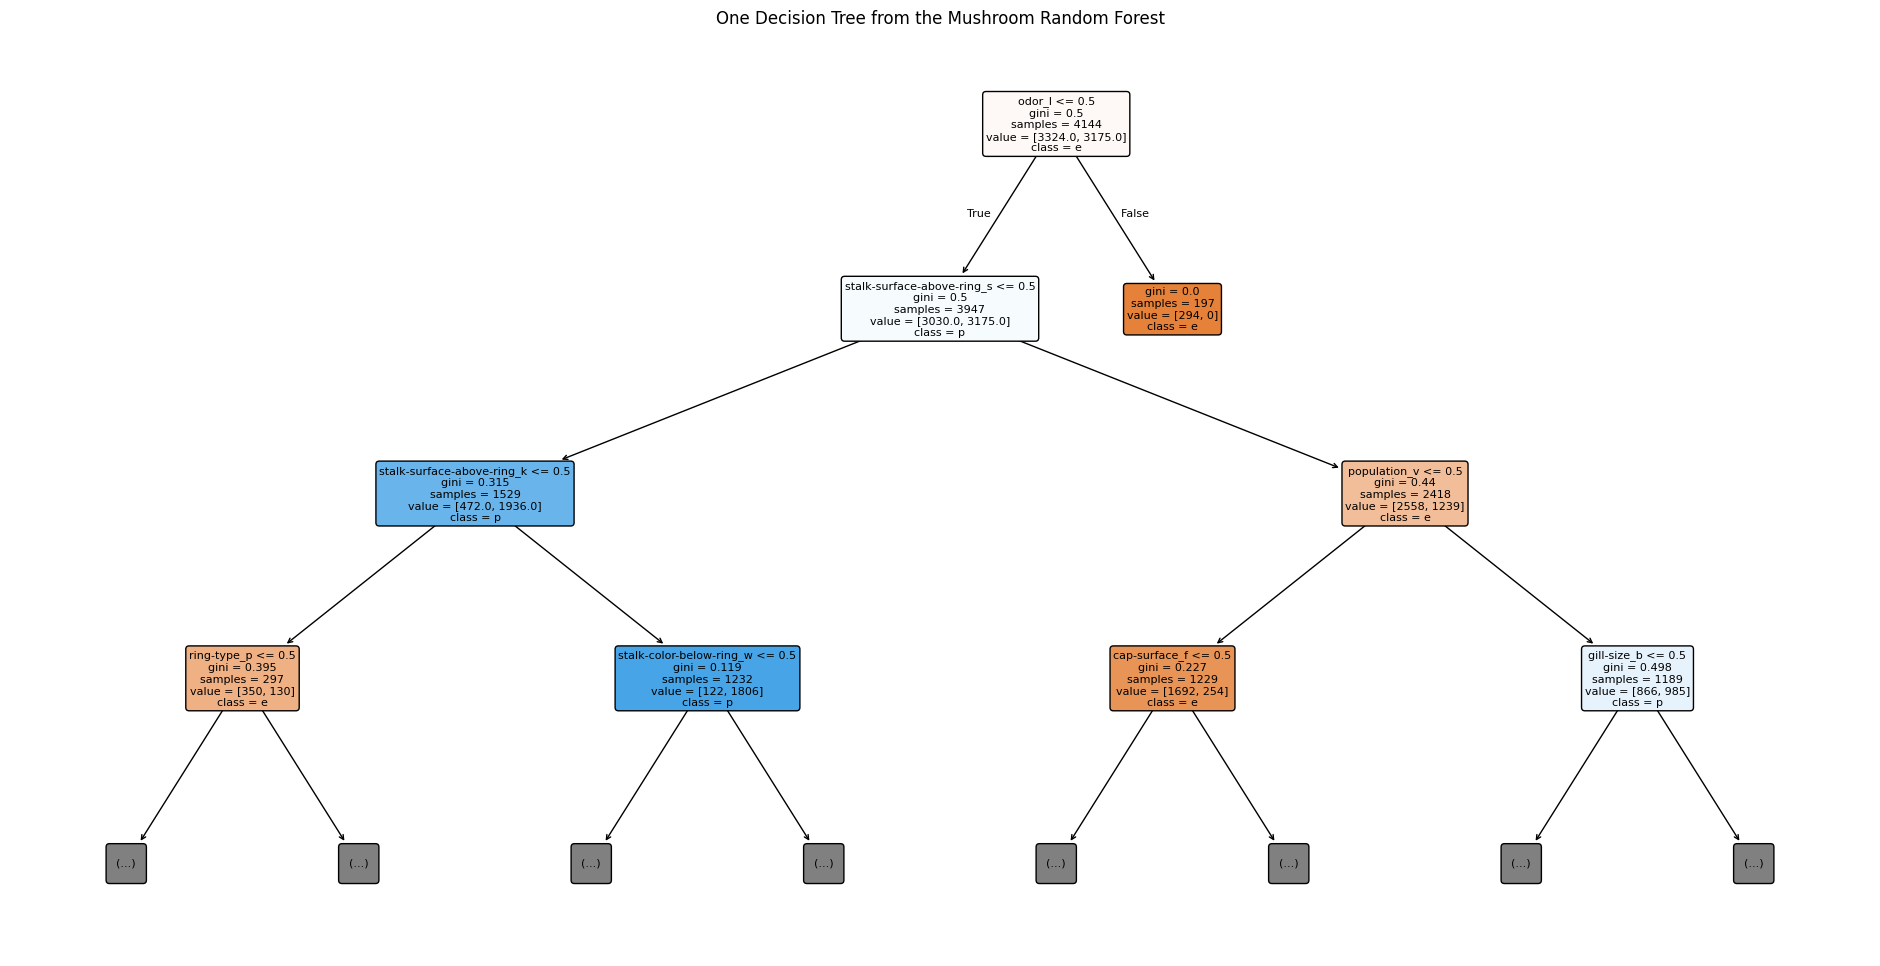

In [53]:
from sklearn.tree import plot_tree

# Get the first decision tree from the mushroom Random Forest
mushroom_tree = Forest_model.estimators_[0]

plt.figure(figsize=(24, 12))

plot_tree(
    mushroom_tree,
    feature_names=mushroom_X_encoded.columns,
    class_names=["e", "p"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("One Decision Tree from the Mushroom Random Forest")
plt.show()

In [54]:
#Show how accurate the model was able to predict
print("Mushroom Accuracy:")
print(accuracy_score(mushroom_y_test, mushroom_predictions))

#Show how performance rate
print("Mushroom Report:")
print(classification_report(mushroom_y_test, mushroom_predictions))

Mushroom Accuracy:
1.0
Mushroom Report:
              precision    recall  f1-score   support

           e       1.00      1.00      1.00       842
           p       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



### Random Forest Bean

In [55]:
Forest_model.fit(
    dry_bean_X_train,
    dry_bean_y_train
)

dry_bean_predictions = Forest_model.predict(dry_bean_X_test)

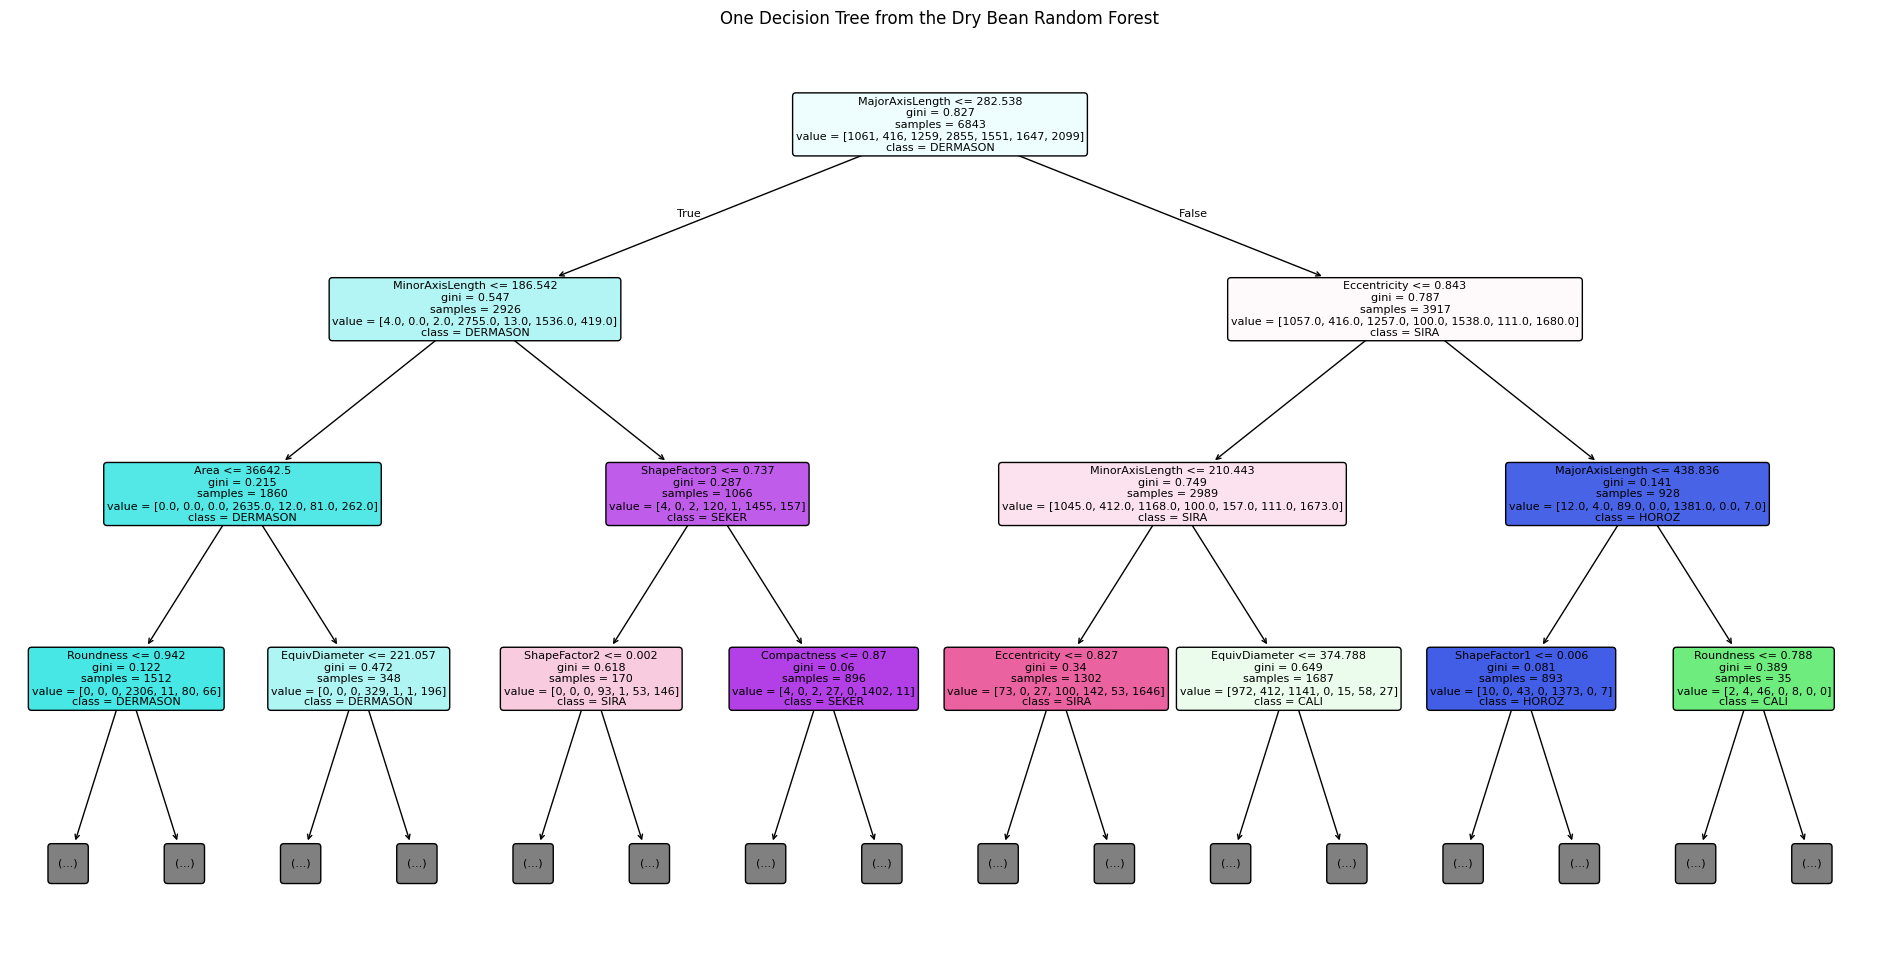

In [56]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Get the first decision tree from the Dry Bean Random Forest
dry_bean_tree = Forest_model.estimators_[0]

plt.figure(figsize=(24, 12))

plot_tree(
    dry_bean_tree,
    feature_names=dry_bean_X.columns,
    class_names=Forest_model.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("One Decision Tree from the Dry Bean Random Forest")
plt.show()

In [57]:
print("Dry Bean Accuracy:")
print(accuracy_score(dry_bean_y_test, dry_bean_predictions))

print("Dry Bean Report:")
print(classification_report(dry_bean_y_test, dry_bean_predictions))

Dry Bean Accuracy:
0.9225119353654058
Dry Bean Report:
              precision    recall  f1-score   support

    BARBUNYA       0.94      0.92      0.93       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.95      0.94       326
    DERMASON       0.91      0.91      0.91       709
       HOROZ       0.97      0.94      0.96       386
       SEKER       0.93      0.94      0.94       406
        SIRA       0.87      0.87      0.87       527

    accuracy                           0.92      2723
   macro avg       0.94      0.94      0.94      2723
weighted avg       0.92      0.92      0.92      2723



Accuracy shows the % of predictions were correct

Macro average shows the % of average performance across the classes.

Weighted average shows the % of performance accounting for how many examples are in each class

Precision shows the % of predictions were correct in a class

Recall shows the % of actual examples all the model found

F1-score is the mean of Percision and Recall

Support is the number of examples

## Confusion Matrix

### Mushroom

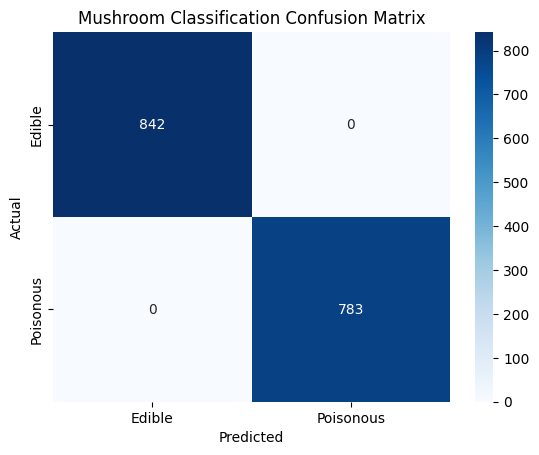

In [58]:
# Create the mushroom confusion matrix
mushroom_cm = confusion_matrix(
    mushroom_y_test,
    mushroom_predictions,
    labels=["e", "p"]
)

sns.heatmap(
    mushroom_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Edible", "Poisonous"],
    yticklabels=["Edible", "Poisonous"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Mushroom Classification Confusion Matrix")
plt.show()

### Bean

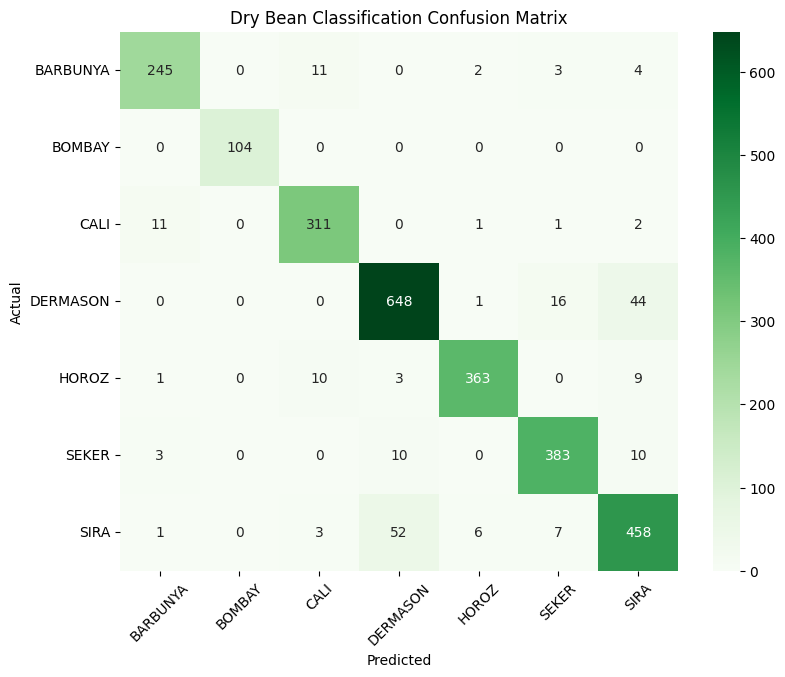

In [59]:
# Create the dry bean confusion matrix
dry_bean_labels = [
    "BARBUNYA",
    "BOMBAY",
    "CALI",
    "DERMASON",
    "HOROZ",
    "SEKER",
    "SIRA"
]

dry_bean_cm = confusion_matrix(
    dry_bean_y_test,
    dry_bean_predictions,
    labels=dry_bean_labels
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    dry_bean_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=dry_bean_labels,
    yticklabels=dry_bean_labels
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Dry Bean Classification Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()